# IT5514: Sri Lankan recorded-dispatch forecasting

**D.V.S Sandaru Rashmika — 269182L**  
MSc in Artificial Intelligence, University of Moratuwa

AI-assisted research notebook. This executed notebook calls the canonical scripts; no separate model implementation or invented outputs are used. The experiment protocol freezes the task and model search before holdout scoring. Read the report, dataset card and disclosure before submitting.

In [1]:
from pathlib import Path
import sys, subprocess, json
import numpy as np, pandas as pd
from IPython.display import display, Image
ROOT = Path.cwd().resolve()
if ROOT.name == '04_notebooks': ROOT = ROOT.parent
assert (ROOT / '03_code').exists(), 'Run from the project root or notebooks folder.'
sys.path.insert(0, str(ROOT / '03_code'))
def run_script(name):
    result = subprocess.run([sys.executable, str(ROOT/'03_code'/name)], text=True, capture_output=True, check=True, cwd=ROOT)
    print(result.stdout[-4500:])
    if result.stderr: print('Diagnostics:', result.stderr[-2000:])
print('Python:', sys.version)
print('Project folders found:', sorted(p.name for p in ROOT.iterdir() if p.is_dir() and not p.name.startswith('.')))

Python: 3.13.1 (main, Dec  3 2024, 17:59:52) [Clang 16.0.0 (clang-1600.0.26.4)]
Project folders found: ['00_requirements', '02_data', '03_code', '04_notebooks']


## 1. Requirements and frozen protocol

The guide requires a local dataset, a new non-deep-learning algorithm, evaluation, XAI and critical discussion. The main model is Gaussian Process Regression, absent from the supplied lecture/OCR corpus. RF, SVR and linear regression are taught comparators. The protocol uses calendar-based expanding validation and one frozen test period.

In [2]:
protocol = json.loads((ROOT/'00_requirements/Experiment_Protocol.json').read_text())
print('Task:', protocol['task'])
display(pd.DataFrame(protocol['validation_folds']))
print('Heldout period:', protocol['test_start'], 'to', protocol['test_end'])
print('Selection metric:', protocol['selection_metric'])

Task: At the end of local calendar day t-1, predict the total recorded dispatch energy during day t; assume t-1 telemetry is complete and available. This is a retrospective one-day-ahead rolling-input forecast with frozen parameters, not a fixed-origin multi-step forecast.


,train_end,validation_start,validation_end
0,2024-03-31,2024-04-01,2024-06-30
1,2024-06-30,2024-07-01,2024-09-30
2,2024-09-30,2024-10-01,2024-12-31


Heldout period: 2025-01-01 to 2025-04-07
Selection metric: Unweighted mean of the three fold MAEs, MWh; lower is better


## 2. Acquire and reconstruct the Sri Lankan target

The versioned public release is credited to Coombes, Hunt and Bloomfield, using PUCSL records. Deduplicate plant/timestamp keys, convert UTC to Asia/Colombo, integrate MW × 0.25 hours, and apply completeness gates. There is no target interpolation. The original daily CSV is retained for comparison, not used as the modelling target.

In [3]:
run_script('prepare_data.py')
audit = json.loads((ROOT/'05_experiments/data_audit.json').read_text())
table = pd.read_csv(ROOT/'02_data/processed/modelling_table.csv', parse_dates=['date']).set_index('date')
display(table.head())
display(table.groupby('split').target_MWh.agg(['count','mean','std']))
assert audit['published_vs_unconverted_undeduplicated_MW_sum_max_abs_difference'] == 0

{
  "raw_rows": 2902337,
  "duplicate_key_rows_removed": 29875,
  "conflicting_duplicate_keys": 0,
  "raw_missing_values": 2394,
  "deduplicated_missing_values": 2376,
  "raw_negative_values": 1276,
  "deduplicated_negative_values": 1264,
  "plants_ever_present": 44,
  "timestamps": 79489,
  "calendar_days": 829,
  "raw_first_local_timestamp": "2023-01-01 05:30:00+05:30",
  "raw_last_local_timestamp": "2025-04-08 05:30:00+05:30",
  "partial_days": [
    "2023-01-01",
    "2025-04-08"
  ],
  "days_with_explicit_nulls": 12,
  "valid_target_days": 815,
  "eligible_rows": 756,
  "development_rows": 659,
  "test_rows": 97,
  "published_ratio_median": 4.041427122083192,
  "published_ratio_min": 4.0,
  "published_ratio_max": 4.0519368532767315,
  "zero_system_intervals": 10,
  "negative_clip_max_daily_difference_MWh": 39.0,
  "negative_clip_total_difference_MWh": 549.25,
  "reconstructed_2024_GWh": 15421.75775,
  "daily_mean_2024_GWh": 42.135950136612024,
  "unit_corroboration_2024_12_24_MWh"

,lag1_MWh,lag2_MWh,lag7_MWh,lag14_MWh,rolling7_mean_MWh,rolling7_std_MWh,dow_sin,dow_cos,year_sin,year_cos,trend_days,target_MWh,split
date,,,,,,,,,,,,,
2023-01-16,32176.25,34124.25,35904.50,33782.75,35551.071429,1633.242676,0.000000,1.000000,0.255188,0.966892,15,34528.00,development
2023-01-17,34528.00,32176.25,37022.75,36654.25,35354.428571,1661.473355,0.781831,0.623490,0.271782,0.962359,16,36487.75,development
2023-01-18,36487.75,34528.00,36557.75,37757.75,35278.000000,1593.903015,0.974928,-0.222521,0.288296,0.957541,17,36927.75,development
2023-01-19,36927.75,36487.75,36573.50,38428.00,35330.857143,1640.907659,0.433884,-0.900969,0.304725,0.952440,18,36564.00,development
2023-01-20,36564.00,36927.75,36498.50,32267.00,35329.500000,1639.882955,-0.433884,-0.900969,0.321064,0.947057,19,36073.00,development


,count,mean,std
split,,,
development,659,39964.600531,4567.006431
test,97,42751.811856,3707.979166


## 3. Execute validation-only selection and frozen evaluation

Every candidate uses the same eligible validation dates. Choices are written to `selected_models_before_test.json` before the script computes heldout predictions. This cell reruns the frozen experiment for reproducibility; it does not alter the design in response to scores.

In [4]:
run_script('train_evaluate.py')
cv = pd.read_csv(ROOT/'05_experiments/cv_results.csv')
selected = json.loads((ROOT/'05_experiments/selected_models_before_test.json').read_text())
display(pd.DataFrame(selected).T[['config_id','config','CV_MAE_MWh']])
display(cv.groupby(['model','config_id']).MAE_MWh.mean().unstack(0))

Linear regression 0 {} CV MAE 2182.099
Random forest 0 {'max_depth': 6, 'min_samples_leaf': 2} CV MAE 1876.87
Random forest 1 {'max_depth': 6, 'min_samples_leaf': 5} CV MAE 1827.817
Random forest 2 {'max_depth': 6, 'min_samples_leaf': 10} CV MAE 1861.768
Random forest 3 {'max_depth': None, 'min_samples_leaf': 2} CV MAE 1868.751
Random forest 4 {'max_depth': None, 'min_samples_leaf': 5} CV MAE 1823.154
Random forest 5 {'max_depth': None, 'min_samples_leaf': 10} CV MAE 1858.648
SVR 0 {'C': 1, 'epsilon': 0.05} CV MAE 2123.439
SVR 1 {'C': 1, 'epsilon': 0.15} CV MAE 2248.267
SVR 2 {'C': 10, 'epsilon': 0.05} CV MAE 2246.575
SVR 3 {'C': 10, 'epsilon': 0.15} CV MAE 2283.809
SVR 4 {'C': 100, 'epsilon': 0.05} CV MAE 3814.08
SVR 5 {'C': 100, 'epsilon': 0.15} CV MAE 4190.989
GPR 0 {'kernel': 'RBF', 'initial_length_scale': 1.0} CV MAE 2004.104
GPR 1 {'kernel': 'RBF', 'initial_length_scale': 5.0} CV MAE 2004.106
GPR 2 {'kernel': 'Matern1.5', 'initial_length_scale': 1.0} CV MAE 1998.546
GPR 3 {'kerne

,config_id,config,CV_MAE_MWh
Linear regression,0,{},2182.098663
Random forest,4,"{'max_depth': None, 'min_samples_leaf': 5}",1823.153744
SVR,0,"{'C': 1, 'epsilon': 0.05}",2123.438772
GPR,5,"{'kernel': 'Matern2.5', 'initial_length_scale'...",1997.960874
Persistence,0,{},2911.487726
Seasonal naive,0,{},3025.287998


model,GPR,Linear regression,Persistence,Random forest,SVR,Seasonal naive
config_id,,,,,,
0,2004.104454,2182.098663,2911.487726,1876.870075,2123.438772,3025.287998
1,2004.106166,NaN,NaN,1827.817244,2248.266528,NaN
2,1998.545641,NaN,NaN,1861.767881,2246.574863,NaN
3,1998.550487,NaN,NaN,1868.750895,2283.809085,NaN
4,1997.981237,NaN,NaN,1823.153744,3814.079579,NaN
5,1997.960874,NaN,NaN,1858.648483,4190.988528,NaN


In [5]:
metrics = pd.read_csv(ROOT/'05_experiments/test_metrics.csv')
display(metrics.sort_values('MAE_MWh'))
uncertainty = json.loads((ROOT/'05_experiments/uncertainty.json').read_text())
print('Uncertainty:', uncertainty)
display(pd.DataFrame(json.loads((ROOT/'05_experiments/paired_block_bootstrap.json').read_text())))

,model,MAE_MWh,RMSE_MWh,R2,CV_MAE_MWh,final_fit_seconds,MAE_skill_vs_seasonal_naive
2,SVR,1534.205166,2406.244074,0.574494,2123.438772,0.012527,0.325357
3,GPR,1598.668728,2491.533548,0.543796,1997.960874,0.257514,0.297011
1,Random forest,1607.303920,2322.076833,0.603741,1823.153744,0.370813,0.293213
0,Linear regression,2042.924487,2805.146803,0.421721,2182.098663,0.001489,0.101656
5,Seasonal naive,2274.100515,3172.516398,0.260337,3025.287998,0.000000,0.000000
4,Persistence,3254.770619,4243.261930,-0.323200,2911.487726,0.000000,-0.431234


Uncertainty: {'nominal_coverage': 0.95, 'empirical_coverage': 0.9278350515463918, 'mean_width_MWh': 9339.758439632245, 'mean_std_MWh': 2382.635220163056, 'gaussian_NLPD': 9.274471504840088, 'n_test': 97, 'includes_white_kernel_observation_noise': True, 'interval_recalibrated_on_test': False}


,comparator,mean_difference_MWh,ci95_lower,ci95_upper,block_length,replicates,meaning
0,Seasonal naive,-675.431787,-1134.415043,-221.085975,7,2000,GPR absolute error minus comparator absolute e...
1,Seasonal naive,-675.431787,-1084.423637,-257.293362,14,2000,GPR absolute error minus comparator absolute e...
2,Random forest,-8.635192,-187.758715,181.144743,7,2000,GPR absolute error minus comparator absolute e...
3,Random forest,-8.635192,-184.428846,167.606040,14,2000,GPR absolute error minus comparator absolute e...


## 4. Explain and diagnose

Grouped block permutation measures the fitted model’s reliance, while ablation retrains a different restricted model. Local replacement bars are non-additive sensitivity checks, not SHAP or causal effects. PDPs may break dependence between lagged predictors. All raw explanation data are saved.

                             mean         std         min          max
group                                                                 
Demand history        1491.556076  517.863779  456.498602  2055.380342
Weekly calendar        915.946209  487.678304    0.000000  1459.526715
Annual cycle / trend    84.583684   50.072288   -3.111800   165.005476
FIGURES 9

Diagnostics: Matplotlib is building the font cache; this may take a moment.
/Users/sandaruvithanage/Downloads/269182L_Advanced_Machine_Learning_Assignment/work/reproduction/03_code/explain_and_plot.py:24: UserWarning: AutoDateLocator was unable to pick an appropriate interval for this date range. It may be necessary to add an interval value to the AutoDateLocator's intervald dictionary. Defaulting to 6.
  plt.savefig(FIG/(name+'.png'),bbox_inches='tight',facecolor='white');plt.close()



,group,mean,std,min,max
0,Demand history,1491.556076,517.863779,456.498602,2055.380342
1,Weekly calendar,915.946209,487.678304,0.000000,1459.526715
2,Annual cycle / trend,84.583684,50.072288,-3.111800,165.005476


,kind,setting,MAE_MWh,RMSE_MWh,R2,kernel
0,RF_seed,7,1630.519330,2348.273214,0.594750,NaN
1,RF_seed,42,1607.303920,2322.076833,0.603741,NaN
2,RF_seed,2026,1633.605176,2344.459406,0.596065,NaN
3,GPR_initialization,0.5,1598.670335,2491.531804,0.543796,"2.2**2 * Matern(length_scale=8.23, nu=2.5) + W..."
4,GPR_initialization,1.0,1598.668728,2491.533548,0.543796,"2.2**2 * Matern(length_scale=8.23, nu=2.5) + W..."
5,GPR_initialization,2.0,1598.670325,2491.531755,0.543796,"2.2**2 * Matern(length_scale=8.23, nu=2.5) + W..."
6,retrained_ablation,GPR history only,2009.494974,2731.428179,0.451716,"1.22**2 * Matern(length_scale=2.81, nu=2.5) + ..."
7,retrained_ablation,GPR calendar only,2422.578364,3372.909341,0.163944,"1.48**2 * Matern(length_scale=3.91, nu=2.5) + ..."


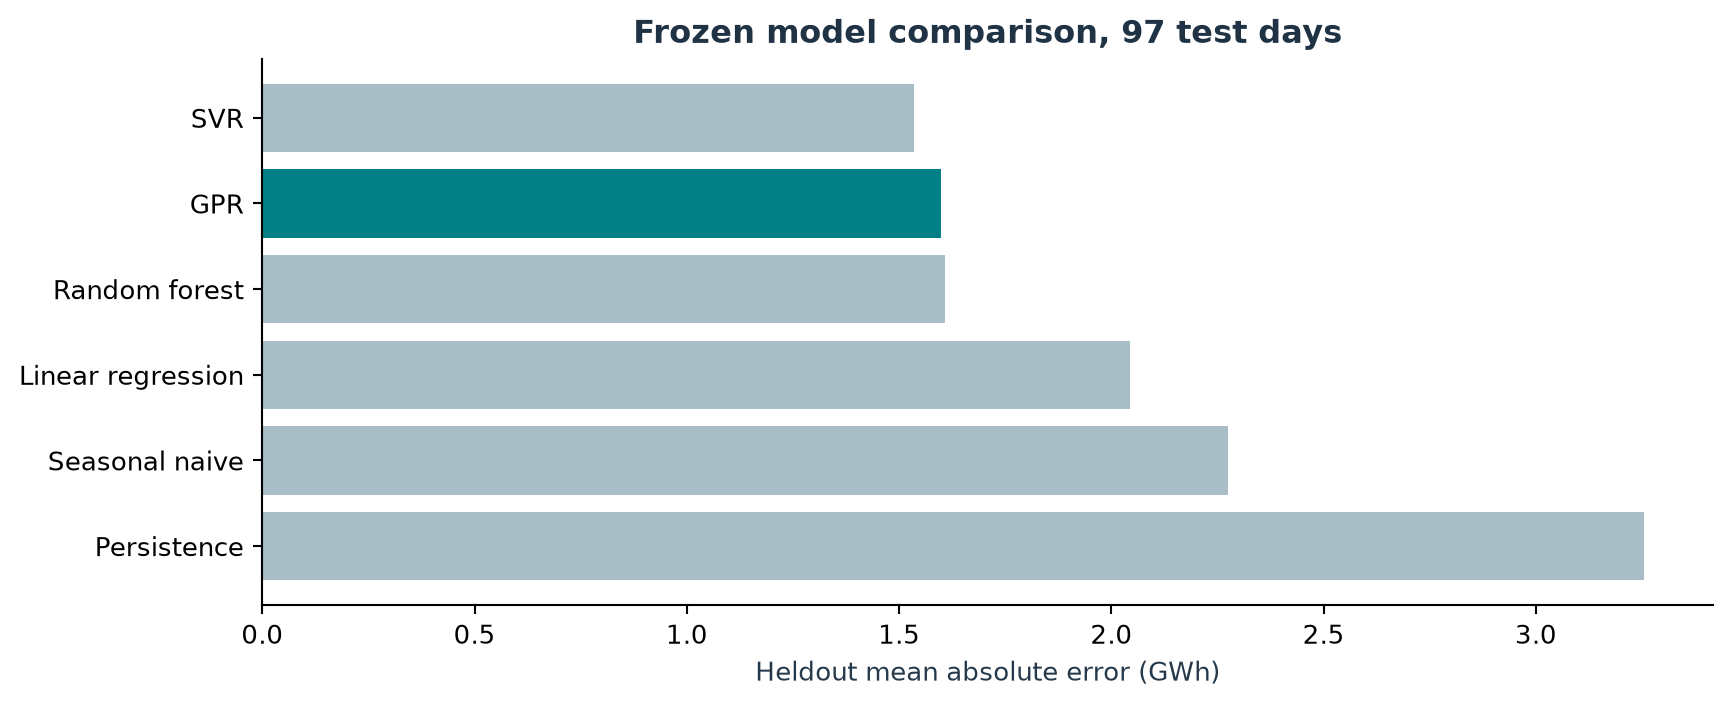

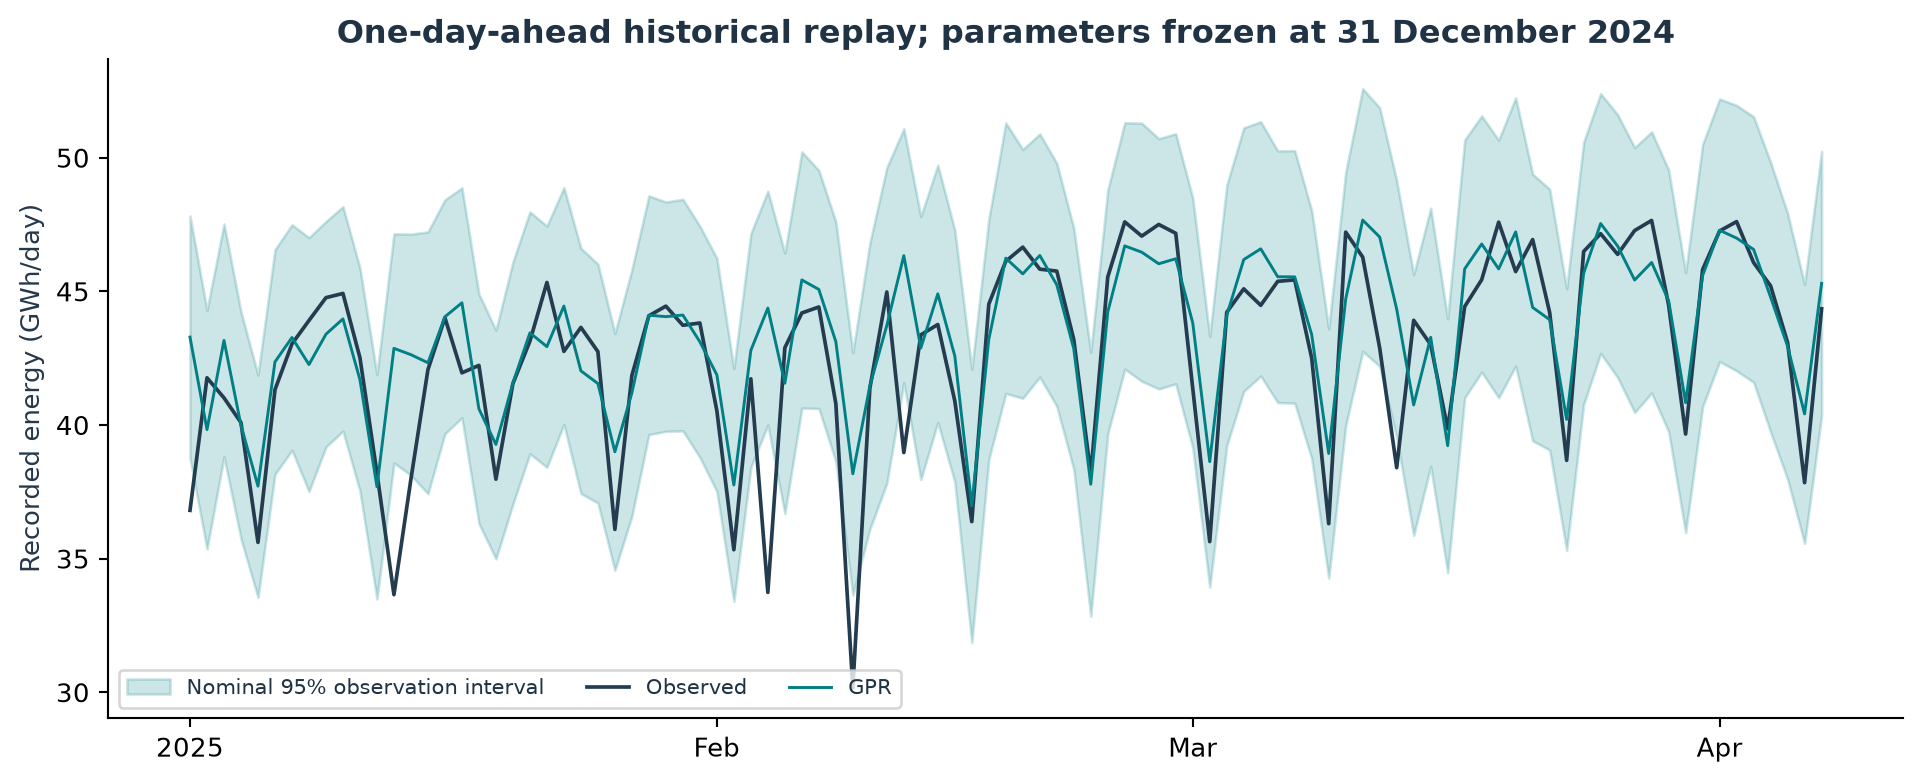

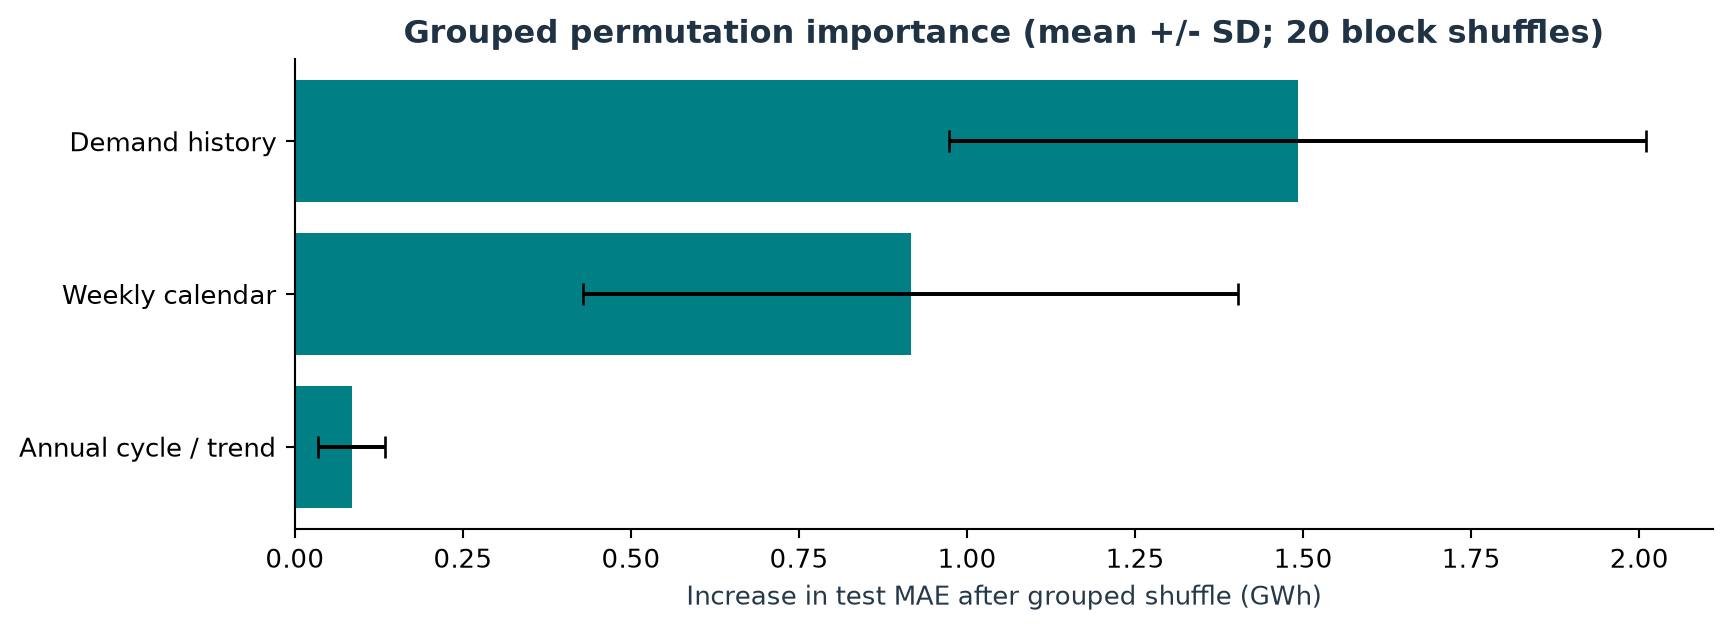

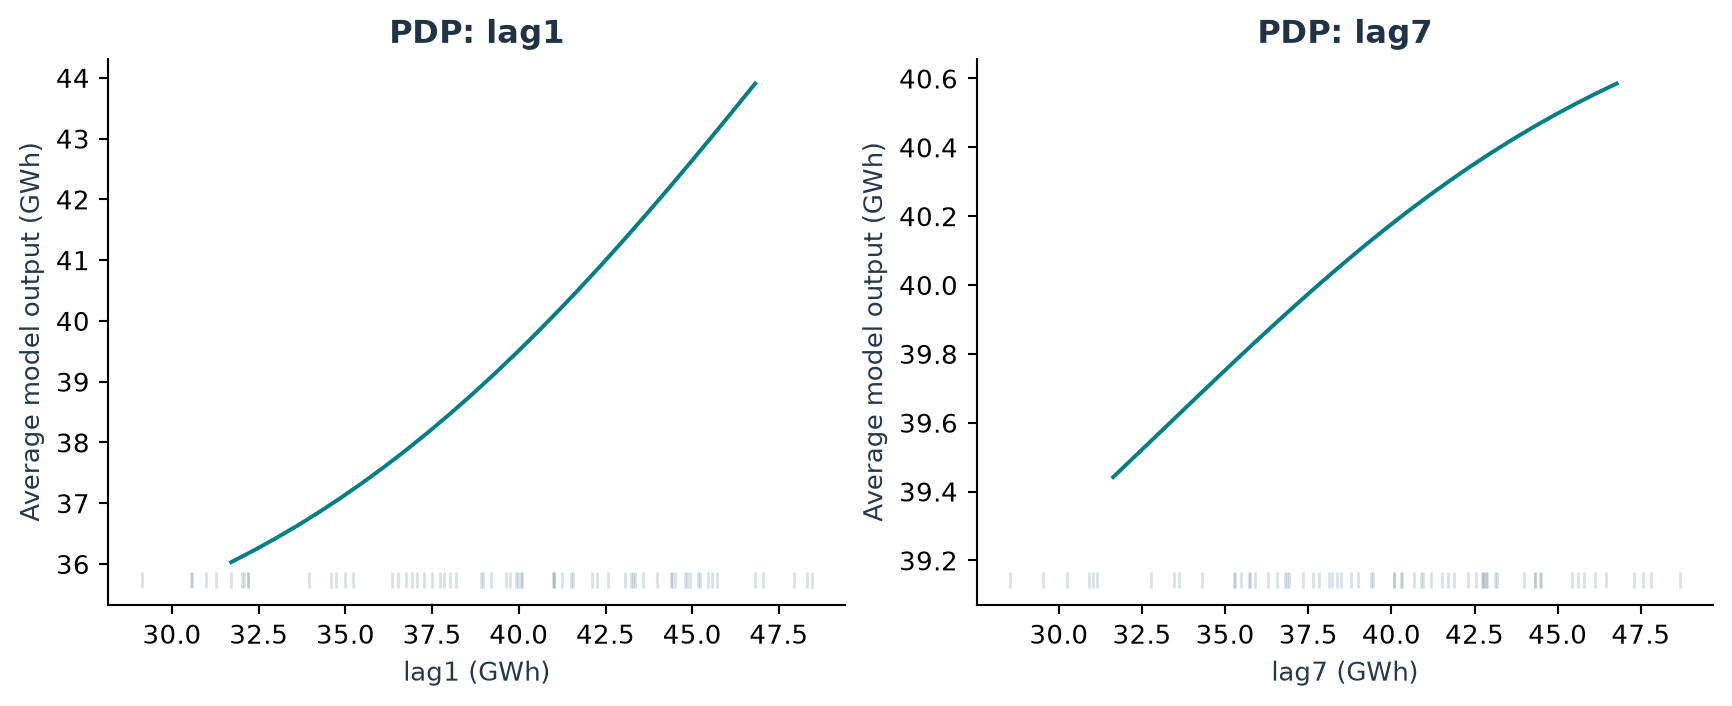

In [6]:
run_script('explain_and_plot.py')
display(pd.read_csv(ROOT/'05_experiments/grouped_permutation_summary.csv'))
display(pd.read_csv(ROOT/'05_experiments/sensitivity_ablations.csv'))
for filename in ['03_model_comparison.png','04_test_forecast.png','06_grouped_importance.png','07_partial_dependence.png']:
    display(Image(filename=str(ROOT/'06_figures'/filename), width=900))

## 5. Error analysis and interpretation

The recorded GPR improves the weekly baseline but does not dominate taught comparators. Its empirical interval coverage is below nominal on a short test. Several large errors coincide with advance-known Sri Lankan holidays omitted from the frozen feature set. A holiday-aware revision needs a fresh holdout or new outer validation, rather than optimizing on this test. Recorded dispatch is a coverage-limited demand proxy. Publication latency, changing plant coverage and national aggregation restrict operational and fairness claims.

In [7]:
display(pd.read_csv(ROOT/'05_experiments/worst_errors.csv').head(10))
display(pd.read_csv(ROOT/'05_experiments/error_slices.csv'))
print('Residual diagnostics:', json.loads((ROOT/'05_experiments/residual_diagnostics.json').read_text()))

,date,actual_MWh,Linear regression,Random forest,SVR,GPR_std_MWh,GPR,Persistence,Seasonal naive,GPR_lower95_MWh,GPR_upper95_MWh,GPR_error_MWh,absolute_error_MWh
0,2025-02-04,33735.00,44199.797726,42324.355895,43824.550119,2233.224284,44373.330760,41725.75,44085.25,39996.291593,48750.369926,10638.330760,10638.330760
1,2025-01-13,33650.00,41476.196345,42952.001001,42730.124218,2187.428198,42866.454845,38203.75,41320.00,38579.174358,47153.735331,9216.454845,9216.454845
2,2025-02-09,30152.00,39067.207571,36652.420384,37864.234216,2313.131641,38173.201108,40800.50,35332.25,33639.546400,42706.855815,8021.201108,8021.201108
3,2025-02-12,38968.00,46041.688783,44677.972818,45267.369807,2423.736486,46336.544041,44975.75,42889.25,41586.107820,51086.980262,7368.544041,7368.544041
4,2025-01-01,36805.75,43065.762673,43264.167277,42980.243308,2312.738243,43287.523992,43256.25,34760.50,38754.640330,47820.407654,6481.773992,6481.773992
5,2025-03-13,38402.50,45290.808282,42552.037832,44582.593292,2448.019010,44334.466582,42879.25,45374.75,39536.437489,49132.495674,5931.966582,5931.966582
6,2025-01-14,37978.25,40348.986339,41132.178882,42944.886167,2301.404783,42630.413979,33650.00,43034.50,38119.743491,47141.084466,4652.163979,4652.163979
7,2025-03-12,42879.25,47844.478860,44329.854806,46716.535530,2468.564276,47031.566618,46280.50,44477.25,42193.269543,51869.863693,4152.316618,4152.316618
8,2025-03-14,43915.25,41815.489549,40073.694036,41544.371872,2489.119860,40749.729658,38402.50,45429.75,35871.144379,45628.314937,-3165.520342,3165.520342
9,2025-03-02,35635.25,39973.749400,37314.278007,38757.915837,2393.476903,38626.793863,41369.00,38158.50,33935.665336,43317.922390,2991.543863,2991.543863


,slice,level,model,n,MAE_MWh,RMSE_MWh,R2
0,month,2025-01,GPR,31,1657.433521,2557.148195,0.264175
1,month,2025-01,Seasonal naive,31,2403.991935,3205.899197,-0.156545
2,month,2025-01,Random forest,31,1763.884633,2541.114456,0.273373
3,month,2025-02,GPR,28,1823.708141,3079.373355,0.504016
4,month,2025-02,Seasonal naive,28,2548.812500,3879.139256,0.212929
5,month,2025-02,Random forest,28,1876.388329,2735.199648,0.608690
6,month,2025-03,GPR,31,1529.221682,2012.811462,0.622722
7,month,2025-03,Seasonal naive,31,2098.056452,2663.904317,0.339166
8,month,2025-03,Random forest,31,1392.514639,1863.625519,0.676576
9,month,2025-04,GPR,7,745.818196,1091.308104,0.874822


Residual diagnostics: {'lag1_autocorrelation': -0.01860955825402813, 'lag7_autocorrelation': -0.007311049596700428, 'mean_signed_error_actual_minus_prediction_MWh': -682.7866614514235}


## 6. Independent checks and interface launch

Verify prior-calendar-day lags, rolling windows, temporal separation, development-only transforms, saved-model predictions, all main metrics and validation-only selection. To launch the UI, run `python 03_code/app.py` from a terminal and open `http://127.0.0.1:8765`. It uses the actual frozen model; no cloud account is needed.

In [8]:
run_script('validate_project.py')
checks = json.loads((ROOT/'05_experiments/verification.json').read_text())
assert checks['status'] == 'passed'
print('Independent checks passed:', checks['passed'])

[
  {
    "check": "unique chronological daily modelling rows",
    "passed": true
  },
  {
    "check": "every lag and rolling value uses only prior calendar days",
    "passed": true
  },
  {
    "check": "chronological split and test held to 2025",
    "passed": true
  },
  {
    "check": "targets have 96 timestamps and no explicit missing plant values",
    "passed": true
  },
  {
    "check": "scaler fitted on development features only",
    "passed": true
  },
  {
    "check": "GPR stores only development labels",
    "passed": true
  },
  {
    "check": "saved model predictions reproduce",
    "passed": true
  },
  {
    "check": "prediction rows match test dates and targets",
    "passed": true
  },
  {
    "check": "every main metric independently recomputed from stored predictions",
    "passed": true
  },
  {
    "check": "all selected configurations minimize validation MAE only",
    "passed": true
  }
]

Independent checks passed: 10


## Student review

Explain the GP posterior, why the raw daily file was rebuilt, why rolling observed test inputs are legitimate for the declared task, and why local explanations do not prove causal effects. Retain the AI disclosure, confirm module rules and exact Moodle cutoff, review all artefacts, and upload personally. No lecturer approval, independent authorship declaration or Moodle upload is claimed.